# Data Overview and Spike Definition

## Objective

This notebook explores the master dataset and establishes the definition of an imbalance price spike used throughout the thesis (Objective O1). The definition determines which periods are treated as rare events, and therefore underpins every later model and sensitivity analysis.

## Data

- **Source:** `master.parquet`, built by `src/data_prep.py` from the raw extracts
- **Period:** 1 February 2022 to 30 September 2026, half-hourly (UTC)
- **Key variables:** imbalance price `pimb_eur` (€/MWh), day-ahead price `da_price_eur` (€/MWh), net imbalance volume `niv_mwh` (MWh)

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from config.paths import PROCESSED_DIR

pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_parquet(PROCESSED_DIR / "master.parquet").set_index("time_utc")
df.index.min(), df.index.max(), df.shape

(Timestamp('2022-02-01 00:00:00+0000', tz='UTC'),
 Timestamp('2026-09-30 23:30:00+0000', tz='UTC'),
 (81744, 17))

## 1. The spike variable: the PIMB–DA spread

> **Definition (spread)**
>
> $$S_t = P^{\text{IMB}}_t - P^{\text{DA}}_t$$
>
> where $P^{\text{IMB}}_t$ is the imbalance price and $P^{\text{DA}}_t$ the day-ahead price for settlement period $t$.

Spikes are defined on the spread rather than on the imbalance price itself. The imbalance price follows the day-ahead price, which carries the gas-driven price level and the daily demand shape. Subtracting the day-ahead price for the same period removes both, so that:

- a spike reflects balancing conditions rather than a high day-ahead price,
- it measures the exposure of a participant who traded at the day-ahead price, and
- spikes are comparable across periods of high and low gas prices and across hours of the day.

The forecasting target remains the imbalance price; the spread is used only to label spikes.

In [2]:
df["spread"] = df["pimb_eur"] - df["da_price_eur"]

cols = ["pimb_eur", "da_price_eur", "spread", "niv_mwh"]
summary = df[cols].describe(percentiles=[.01, .05, .5, .95, .99]).T
summary["missing_%"] = df[cols].isna().mean() * 100
summary

,count,mean,std,min,1%,5%,50%,95%,99%,max,missing_%
pimb_eur,"81,445.00",140.10,108.33,-411.72,-15.67,0.00,124.14,361.47,488.06,874.25,0.37
da_price_eur,"81,744.00",141.83,80.50,-30.00,1.00,48.62,121.40,304.10,430.00,705.47,0.00
spread,"81,445.00",-1.67,77.57,-478.54,-167.67,-109.89,-11.71,124.57,248.32,465.13,0.37
niv_mwh,"80,960.00",1.06,27.12,-238.00,-71.90,-42.06,1.13,44.41,66.93,193.16,0.96


In [3]:
d = df[["spread"]].dropna().assign(year=lambda x: x.index.year)
fig = px.box(d, x="year", y="spread", points=False, title="PIMB–DA spread by year")
fig.update_layout(yaxis_title="€/MWh")
fig

## 2. Spike definitions

**Primary: rolling threshold.** A period is a spike if the spread is extreme relative to recent market conditions.

> **Definition (rolling)**
>
> $$\text{spike}^{+}_t = \mathbb{1}\left[S_t > q^{W}_{0.99,\,t}\right], \qquad \text{spike}^{-}_t = \mathbb{1}\left[S_t < q^{W}_{0.01,\,t}\right]$$
>
> where $q^{W}_{\alpha,\,t}$ is the $\alpha$-quantile of $S$ over the trailing window $[\,t - W,\; t\,)$. The 95th and 5th percentiles define less extreme events in the same way. The primary window is $W = 90$ days.

**Benchmark: fixed threshold.** The same quantiles estimated once over the whole sample.

**Optional economic floor.** The rolling threshold can be combined with a minimum spread $c$, so that in calm periods trivially small deviations are not counted:

$$\text{spike}^{+}_t = \mathbb{1}\left[S_t > \max\left(q^{W}_{0.99,\,t},\; c^{+}\right)\right]$$

**Design choices**

- **Trailing window only.** Each threshold uses only periods before $t$, so no information from after the labelled period is used. This is a stricter form of estimating thresholds from training data only.
- **Warm-up.** Data before 1 February 2022 belongs to the previous market design and is not used. Each window therefore requires 30 days of data before producing a threshold; until a full window is available it covers all data since the start of the sample. February 2022 is unlabelled.
- **Quantiles, not mean plus $k$ standard deviations.** The mean and variance are themselves distorted by spikes (Janczura et al., 2013).
- **One threshold for all hours of the day.** Hour-specific thresholds would leave too few observations per threshold and would remove any genuine time-of-day pattern in balancing stress, which is a result to be found rather than assumed away. Time of day enters the models as an input instead.
- **Positive and negative tails are treated separately**, as their drivers differ (Hagfors et al., 2016).

In [4]:
QUANTILES = {"p01": 0.01, "p05": 0.05, "p95": 0.95, "p99": 0.99}

def fixed_thresholds(s):
    # Whole-sample quantiles, repeated for every period.
    return pd.DataFrame({k: s.quantile(q) for k, q in QUANTILES.items()}, index=s.index)

def rolling_thresholds(s, window, min_days=30):
    # Trailing quantiles over `window`, using only periods before t.
    # Until a full window exists, the window covers all data since the start of the sample.
    r = s.rolling(window, min_periods=min_days * 48)
    return pd.DataFrame({k: r.quantile(q) for k, q in QUANTILES.items()}).shift(1)

def with_floor(thr, floor_up, floor_down):
    # Upper thresholds no lower than floor_up, lower thresholds no higher than floor_down.
    out = thr.copy()
    out[["p95", "p99"]] = out[["p95", "p99"]].clip(lower=floor_up)
    out[["p01", "p05"]] = out[["p01", "p05"]].clip(upper=floor_down)
    return out

def label_spikes(s, thr):
    # Boolean spike flags; missing where the spread or the threshold is missing.
    out = pd.DataFrame({
        "up_99": s > thr["p99"], "up_95": s > thr["p95"],
        "down_05": s < thr["p05"], "down_01": s < thr["p01"],
    }).astype("boolean")
    out[~(s.notna() & thr["p99"].notna())] = pd.NA
    return out

In [5]:
FLOOR_UP, FLOOR_DOWN = 100, -100   # €/MWh; placeholder values for the economic floor

s = df["spread"]
thresholds = {
    "roll_90d": rolling_thresholds(s, "90D"),             # primary
    "fixed": fixed_thresholds(s),                         # benchmark
    "roll_30d": rolling_thresholds(s, "30D"),
    "roll_365d": rolling_thresholds(s, "365D"),
}
thresholds["roll_90d_floor"] = with_floor(thresholds["roll_90d"], FLOOR_UP, FLOOR_DOWN)

labels = {name: label_spikes(s, thr) for name, thr in thresholds.items()}
PRIMARY = "roll_90d"

## 3. Comparing the definitions

The spike rate per year shows how evenly each definition spreads events over time. Under a fixed threshold, spikes concentrate in volatile years; a rolling threshold keeps the rate close to the nominal level in every year.

In [6]:
rate = pd.concat({n: lab.groupby(lab.index.year).mean() * 100 for n, lab in labels.items()}, axis=1)

print("Upper tail (p99), % of periods")
display(rate.xs("up_99", axis=1, level=1).round(2))
print("\nLower tail (p01), % of periods")
display(rate.xs("down_01", axis=1, level=1).round(2))

Upper tail (p99), % of periods


,roll_90d,fixed,roll_30d,roll_365d,roll_90d_floor
time_utc,,,,,
2022,1.15,0.48,1.15,1.25,1.15
2023,0.77,0.08,1.32,0.20,0.77
2024,1.47,0.33,1.55,1.60,1.47
2025,1.30,2.49,1.48,2.24,1.30
2026,0.99,1.80,0.99,0.41,0.99



Lower tail (p01), % of periods


,roll_90d,fixed,roll_30d,roll_365d,roll_90d_floor
time_utc,,,,,
2022,1.12,2.86,1.28,0.82,1.12
2023,0.66,0.37,1.02,0.13,0.66
2024,1.28,0.22,0.97,1.55,1.18
2025,1.07,0.85,1.71,1.40,1.07
2026,1.12,0.81,1.21,1.32,1.12


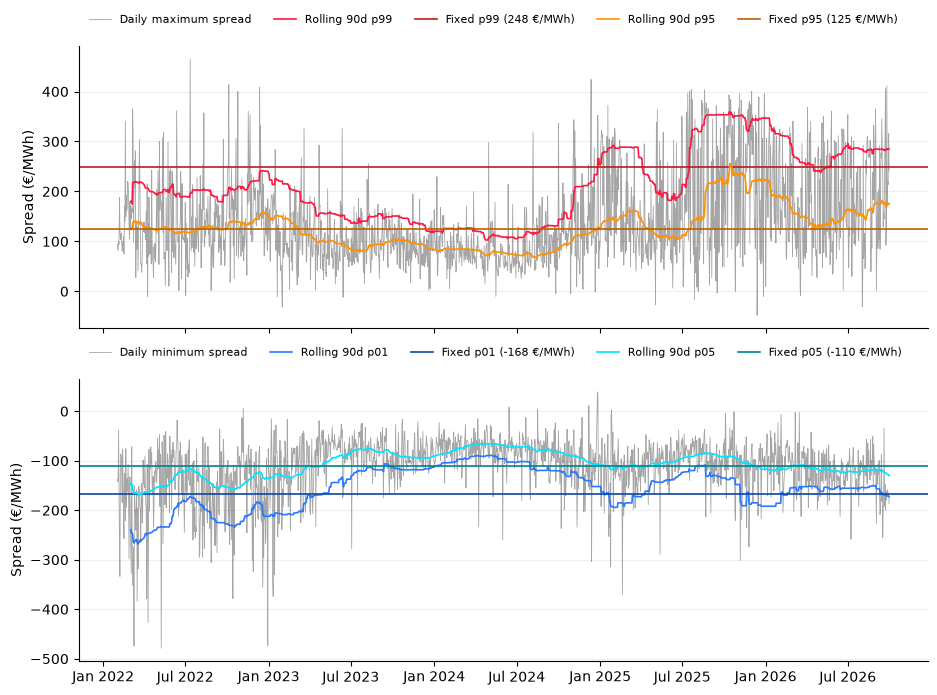

In [7]:
def tail_plot_mpl(tail, ax=None, save=None):
    if tail == "upper":
        data, stat = s.resample("D").max(), "Daily maximum"
        lines = {"p99": ("#ff1744", "#b71c1c"), "p95": ("#ff9100", "#bf5f00")}
    else:
        data, stat = s.resample("D").min(), "Daily minimum"
        lines = {"p01": ("#2979ff", "#0d47a1"), "p05": ("#00e5ff", "#00838f")}

    thr = thresholds[PRIMARY].resample("D").last()
    to_local = lambda idx: idx.tz_convert("Europe/Dublin").tz_localize(None)

    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.plot(to_local(data.index), data, color="black", alpha=0.35, lw=0.6, label=f"{stat} spread")
    for q, (c_roll, c_fixed) in lines.items():
        ax.plot(to_local(thr.index), thr[q], color=c_roll, lw=1.2, label=f"Rolling 90d {q}")
        v = thresholds["fixed"][q].iloc[0]
        ax.axhline(v, color=c_fixed, lw=1.2, label=f"Fixed {q} ({v:.0f} €/MWh)")

    ax.set_ylabel("Spread (€/MWh)")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(ncol=5, fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(0, 1.15))
    if save:
        ax.figure.savefig(save, bbox_inches="tight")
    return ax

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
tail_plot_mpl("upper", axes[0])
tail_plot_mpl("lower", axes[1])
fig.tight_layout()
# fig.savefig("../outputs/figures/spike_thresholds.pdf", bbox_inches="tight")

Agreement between definitions is measured by the Jaccard overlap of their spike sets: the number of periods labelled a spike by both, divided by the number labelled by either. Low overlap means the choice of definition changes which events are studied, which is why the definition is carried through the sensitivity analysis (Objective O4).

In [8]:
up = pd.DataFrame({n: lab["up_99"] for n, lab in labels.items()}).dropna()
jaccard = pd.DataFrame({a: {b: (up[a] & up[b]).sum() / (up[a] | up[b]).sum() for b in up} for a in up})
jaccard.round(2)

,roll_90d,fixed,roll_30d,roll_365d,roll_90d_floor
roll_90d,1.00,0.26,0.62,0.58,1.00
fixed,0.26,1.00,0.29,0.38,0.26
roll_30d,0.62,0.29,1.00,0.46,0.62
roll_365d,0.58,0.38,0.46,1.00,0.58
roll_90d_floor,1.00,0.26,0.62,0.58,1.00


## 4. When spikes occur

Because the spread already removes the day-ahead daily shape, any remaining concentration of spikes at particular hours or months reflects balancing conditions rather than the demand profile.

In [9]:
def spike_heatmap(flag, title):
    local = flag.index.tz_convert("Europe/Dublin")
    heat = flag.groupby([local.hour, local.month]).mean().unstack() * 100
    return px.imshow(heat, aspect="auto", color_continuous_scale="Reds",
                     labels=dict(x="Month", y="Hour (Irish time)", color="% spikes"), title=title)

spike_heatmap(labels[PRIMARY]["up_99"], f"Upper spikes (p99) by hour and month: {PRIMARY}")

In [10]:
spike_heatmap(labels[PRIMARY]["down_01"], f"Lower spikes (p01) by hour and month: {PRIMARY}")

### Check: spikes on the spread versus on the price

The same rolling definition is applied to the imbalance price itself. If price-based spikes concentrate in the evening peak, they are largely following the day-ahead price shape, which supports using the spread.

In [11]:
p = df["pimb_eur"]
labels_price = label_spikes(p, rolling_thresholds(p, "90D"))

both = pd.DataFrame({"spread": labels[PRIMARY]["up_99"], "price": labels_price["up_99"]}).dropna()
overlap = (both["spread"] & both["price"]).sum() / (both["spread"] | both["price"]).sum()
print(f"Jaccard overlap, upper spikes on spread vs price: {overlap:.2f}")

spike_heatmap(labels_price["up_99"], "Upper spikes (p99) on PIMB itself, rolling 90d")

Jaccard overlap, upper spikes on spread vs price: 0.30


## 5. Spike persistence

Spikes in electricity prices tend to cluster (Christensen et al., 2009). The length of consecutive runs of spike periods indicates whether spikes are isolated events or part of sustained episodes of system stress.

In [12]:
def run_lengths(flag):
    f = flag.fillna(False).astype(bool)
    runs = f.groupby((f != f.shift()).cumsum()).agg(["first", "size"])
    return runs.loc[runs["first"], "size"]

for tail in ["up_99", "down_01"]:
    rl = run_lengths(labels[PRIMARY][tail])
    print(f"{tail}: {len(rl)} runs, mean length {rl.mean():.2f} periods, longest {rl.max()} periods")
    display(rl.value_counts().sort_index().head(10).rename("runs"))

up_99: 470 runs, mean length 1.94 periods, longest 13 periods


size
1     281
2      90
3      40
4      25
5      15
6       6
7       3
8       3
9       2
10      1
Name: runs, dtype: int64

down_01: 396 runs, mean length 2.11 periods, longest 30 periods


size
1     236
2      80
3      24
4      16
5      17
6      11
7       2
8       2
9       1
10      2
Name: runs, dtype: int64

## 6. Relation to the net imbalance volume

The thesis models the chain from renewable and demand uncertainty, through the net imbalance volume, to the imbalance price. A first check of that chain is whether spikes occur in the expected direction of system imbalance: upper spikes when the system is short (positive NIV) and lower spikes when it is long.

In [13]:
samp = df[["niv_mwh", "spread"]].dropna().sample(20000, random_state=0)
fig = px.scatter(samp, x="niv_mwh", y="spread", opacity=0.3, render_mode="webgl",
                 title="Spread against NIV (20,000-period sample)")
fig.update_layout(xaxis_title="NIV (MWh)", yaxis_title="Spread (€/MWh)")
fig

In [14]:
niv_bins = pd.qcut(df["niv_mwh"], 20)
(labels[PRIMARY][["up_99", "down_01"]].groupby(niv_bins, observed=True).mean() * 100).round(2)

,up_99,down_01
niv_mwh,,
"(-238.0, -42.062]",0.00,2.94
"(-42.062, -30.705]",0.00,2.77
"(-30.705, -23.867]",0.00,2.44
"(-23.867, -18.608]",0.00,1.69
"(-18.608, -14.498]",0.00,1.79
"(-14.498, -10.844]",0.00,1.77
"(-10.844, -7.625]",0.00,1.27
"(-7.625, -4.62]",0.00,1.42
"(-4.62, -1.687]",0.02,1.42


## 7. The upper price ceiling

From around December 2024 the imbalance price repeatedly reaches a level of roughly €490/MWh that is not present earlier. The mechanism setting this level should be identified, as it bounds the upper tail used for extreme value analysis.

In [15]:
near_cap = p.between(480, 510).groupby(p.index.tz_convert(None).to_period("M")).mean() * 100
fig = px.bar(x=near_cap.index.astype(str), y=near_cap.values,
             labels=dict(x="Month", y="% of periods"),
             title="Share of periods with PIMB between €480 and €510")
display(fig)
p[p > 400].round(0).value_counts().head(10).rename("periods")

pimb_eur
488.00    57
490.00    49
489.00    45
418.00    37
481.00    36
438.00    36
426.00    34
408.00    34
401.00    33
420.00    32
Name: periods, dtype: int64

## 8. Conclusion

**Decisions recorded in this notebook**

- Spikes are defined on the PIMB–DA spread; the forecasting target remains the PIMB.
- Primary definition: trailing 90-day quantiles (99th/1st for rare events, 95th/5th for frequent events), with a 30-day warm-up from 1 February 2022.
- Benchmark: fixed whole-sample quantiles. Sensitivity: 30- and 365-day windows, and the economic floor.
- A single threshold applies to all hours of the day.

**Open questions**

- Mechanism behind the ~€490/MWh ceiling from late 2024.
- Value of the economic floor $c$, to be set with reference to a trading decision.

## References

- Christensen, T.M., Hurn, A.S. and Lindsay, K.A. (2009). It never rains but it pours: Modeling the persistence of spikes in electricity prices. *The Energy Journal*, 30(1), 25–48.
- Christensen, T.M., Hurn, A.S. and Lindsay, K.A. (2012). Forecasting spikes in electricity prices. *International Journal of Forecasting*, 28(2), 400–411.
- Cornell, C., Dinh, N.T. and Pourmousavi, S.A. (2023). A probabilistic forecast methodology for volatile electricity prices in the Australian National Electricity Market. arXiv:2311.07289.
- Hagfors, L.I., Kamperud, H.H., Paraschiv, F., Prokopczuk, M., Sator, A. and Westgaard, S. (2016). Prediction of extreme price occurrences in the German day-ahead electricity market. *Quantitative Finance*, 16(12), 1929–1948.
- Hubert, E., Lolas, D. and Sircar, R. Trading Electrons: Predicting DART Spread Spikes in ISO Electricity Markets. arXiv:2601.05085.
- Janczura, J., Trück, S., Weron, R. and Wolff, R.C. (2013). Identifying spikes and seasonal components in electricity spot price data: A guide to robust modeling. *Energy Economics*, 38, 96–110.
- Lee, S.S. and Mykland, P.A. (2008). Jumps in financial markets: A new nonparametric test and jump dynamics. *Review of Financial Studies*, 21(6), 2535–2563.